# Method D: four ways to find the people

Every multi-person chain starts by deciding where the people are, and an error there cannot be repaired later: a beam pointed at a wall gives a clean, wrong, flat signal. Method D compares four localisation strategies on the same recordings, each followed by the same beam and rate estimation:

1. the strongest range bins (the baseline);
2. clustering of the cells that carry vital motion, in range, angle and slow-time frequency;
3. MUSIC on the dynamic covariance;
4. sparse Bayesian learning over an angle grid.

The scene is the one from Method A: two people at 2.0 m (−25° and +20°) and one at 2.6 m (+5°).

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
from radar import cube, simulate, spatial

people = [simulate.Person(2.0, -25, rr=14, hr=80), simulate.Person(2.0, 20, rr=22, hr=90, amp=0.8),
          simulate.Person(2.6, 5, rr=20, hr=110, amp=0.9)]
x, truth = simulate.simulate(people, duration=60, clutter=[(1.2, 0, 3.0), (3.5, -40, 2.0), (2.0, -25, 0.6)], snr_db=20)
cfg, fs = truth["config"], truth["config"].frame_rate
rp = cube.compensate_aop(cube.range_fft(x))
pos, rax = cube.aop_positions(), cfg.range_axis()
angles = np.arange(-70, 70.5, 1.0)

## 1. Strongest range bins

After static removal the range profile shows where something moves. Taking the $N$ strongest bins at least 30 cm apart (`spatial.pick_ranges`) needs no angle processing at all and works when the beds are lined up along range. It returns one position per bin, so two people in the same bin count as one, and the next pick goes to whatever moves next, here the sidelobe of the same chests.

In [2]:
moving = np.abs(cube.remove_static(rp, axis=0)).mean(axis=(0, 1, 2))
print("strongest moving bins (m):", [round(float(rax[b]), 2) for b in spatial.pick_ranges(moving, 3, cfg.range_resolution)])

strongest moving bins (m): [1.99, 2.58, 2.93]


## 2. Clustering the cells that breathe

Clustering in range, angle and Doppler is the usual way to find moving targets. For breathing it needs one change. A chest moves at a few millimetres per second; within one frame (a few milliseconds) that is far below one bin of a Doppler FFT over the chirps, so every person sits in the zero-velocity bin together with the walls (Method F works this out). Here the third axis is the spectrum over frames instead: for every range bin and every look angle, a delay-and-sum beam over slow time, and its power between 0.1 and 3 Hz (`spatial.vital_rad`). A wall has no power there; a chest has a breathing peak and its harmonics.

The strongest 2 % of the range-angle cells are then clustered with DBSCAN (`spatial.cluster_targets`). The cells are placed in metres, $x = R\sin\theta$ and $y = R\cos\theta$, before clustering, so the neighbourhood radius `eps` is a distance (25 cm) rather than a mix of bins and degrees, and each cluster returns a power-weighted centroid. DBSCAN does not need the number of people; it does need `eps` smaller than the spacing between beds and larger than the spread of one chest on the map. The threshold matters as much: keeping 5 % of the cells instead of 2 % bridges the two people at 2.0 m through their overlapping beams and returns a single cluster between them.

In [3]:
rbins = np.arange(int(1.0 / cfg.range_resolution), int(3.8 / cfg.range_resolution))
rad, f = spatial.vital_rad(rp, pos, angles, fs, rbins=rbins)
found = spatial.cluster_targets(rad, rax[rbins], angles, n=3, quantile=0.98, eps_m=0.25)
for r, a in found:
    print(f"cluster centroid  {r:.2f} m  {a:+.1f} deg")

cluster centroid  1.99 m  -25.3 deg
cluster centroid  2.58 m  +5.4 deg
cluster centroid  1.99 m  +19.5 deg


## 3. MUSIC and 4. sparse Bayesian learning

MUSIC was described in Method A; here it runs on the dynamic snapshots of one range bin, the same snapshots that M-SBL uses.

Sparse Bayesian learning starts from a different model. The snapshots of one range bin are written as
$$
\mathbf Y = \boldsymbol\Phi\,\mathbf X + \mathbf N ,
$$
where the columns of $\boldsymbol\Phi$ are the steering vectors of a fine angle grid and the rows of $\mathbf X$ are the signals arriving from each grid angle. Only a few rows are non-zero, one per person, and the same few rows are non-zero in every snapshot. M-SBL (Wipf and Rao, IEEE TSP 2007) gives each row a zero-mean Gaussian prior with its own variance $\gamma_i$ and learns the $\gamma_i$ from the data:
$$
\boldsymbol\Sigma_y = \sigma^2\mathbf I + \boldsymbol\Phi\,\boldsymbol\Gamma\,\boldsymbol\Phi^H,\qquad
\mathbf M = \boldsymbol\Gamma\boldsymbol\Phi^H\boldsymbol\Sigma_y^{-1}\mathbf Y,\qquad
\gamma_i \leftarrow \frac{\lVert \mathbf M_{i\cdot}\rVert^2 / L}{\gamma_i\,\big(\boldsymbol\Phi^H\boldsymbol\Sigma_y^{-1}\boldsymbol\Phi\big)_{ii}},
$$
the fixed-point form of the update, which converges in a few hundred iterations where plain expectation-maximisation needs thousands. Most $\gamma_i$ shrink to zero and the ones that survive are the angles (`spatial.msbl`); the noise power $\sigma^2$ is taken from the smaller half of the covariance eigenvalues. Unlike MUSIC it needs no number of sources and does not fail with coherent sources, because it fits the snapshots themselves instead of the subspaces of their covariance; it costs an $M\times M$ solve per iteration and its result depends on the grid.

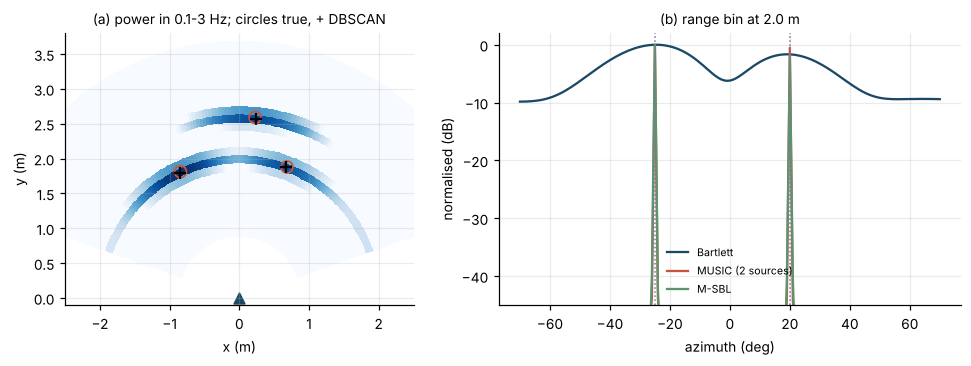

In [4]:
rb = int(round(2.0 / cfg.range_resolution))
y = cube.remove_static(rp, axis=0)[..., rb].mean(axis=2).T            # (12 channels, frames)
r = spatial.covariance(y, 1e-3)
spec = {"Bartlett": spatial.bartlett(r, spatial.steering(pos, angles)),
        "MUSIC (2 sources)": spatial.music(r, spatial.steering(pos, angles), 2),
        "M-SBL": spatial.msbl(y, pos, angles)}

P = rad.sum(axis=2)
R, A = np.meshgrid(rax[rbins], np.deg2rad(angles), indexing="ij")
fig, ax = plt.subplots(1, 2, figsize=(9.0, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].pcolormesh(R * np.sin(A), R * np.cos(A), 10 * np.log10(P / P.max()), vmin=-12, cmap="Blues", shading="auto")
for p in people:
    ax[0].scatter(p.range_m * np.sin(np.deg2rad(p.azimuth_deg)), p.range_m * np.cos(np.deg2rad(p.azimuth_deg)),
                  s=60, facecolors="none", edgecolors="#c8553d", lw=1.2)
for r, a in found:
    ax[0].scatter(r * np.sin(np.deg2rad(a)), r * np.cos(np.deg2rad(a)), marker="+", s=60, color="k")
ax[0].scatter(0, 0, marker="^", s=50, color="#1b4965")
ax[0].set(xlim=(-2.5, 2.5), ylim=(-0.1, 3.8), xlabel="x (m)", ylabel="y (m)",
          title="(a) power in 0.1-3 Hz; circles true, + DBSCAN")
ax[0].set_aspect("equal")
for name, sp in spec.items():
    ax[1].plot(angles, 10 * np.log10(sp / sp.max() + 1e-6), label=name)
for p in people[:2]:
    ax[1].axvline(p.azimuth_deg, color="#8c6d9f", ls=":", lw=1)
ax[1].set(ylim=(-45, 2), xlabel="azimuth (deg)", ylabel="normalised (dB)", title="(b) range bin at 2.0 m")
ax[1].legend(fontsize=7, loc="lower center")
plt.tight_layout()

## What each strategy assumes

| Strategy | Needs the number of people | Two people in one bin | Fails when |
|---|---|---|---|
| strongest range bins | yes | counted as one | beds are side by side; static removal leaves a moving reflection (a fan, a curtain) |
| vital clustering | no | separated if their angles differ by more than the beam spread on the map | `eps` is larger than the bed spacing, the threshold is low enough to bridge two chests, or a chest falls below it |
| MUSIC | yes, per bin | separated below the beamwidth | the sources are coherent (static snapshots), or the model order is wrong |
| M-SBL | no | separated below the beamwidth | the grid is coarse or the noise variance is badly set; slowest of the four |

In our comparison all four were followed by the same MVDR beam and the same rate finders, so differences in the rates could be traced back to the localisation step.